In [1]:
import sys

# Append the parent dir to search path to allow imports from src
sys.path.append("..")

# Tell the Notebook to reload changed code in own packages automatically
%load_ext autoreload
%autoreload 2

# Exploratory Data Analysis
## Basic overview of the images

In [2]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')

train_files = list(TRAIN_PATH.glob('*.jpg'))
test_files = list(TEST_PATH.glob('*.jpg'))

train_files_count = len(train_files)
test_files_count = len(test_files)

test_percent = 100 * test_files_count // (test_files_count + train_files_count)

print(f'There are {train_files_count} training images and {test_files_count} '
      f'test images\n\nThis makes a test size of {test_percent}%.')


There are 5546 training images and 3698 test images

This makes a test size of 40%.


## Basic overview of the labels (DataFrame of `train.csv`)

In [3]:
import pandas as pd

df = pd.read_csv('../data/raw/train.csv')
display(df.shape)
display(df.info())
display(df.head())


(22184, 2)

<class 'pandas.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Image_Label    22184 non-null  str  
 1   EncodedPixels  11836 non-null  str  
dtypes: str(2)
memory usage: 346.8 KB


None

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


## Analysis of the labels DataFrame

- The `df` contains 2 columns. Both are of type `object`: `Image_label` and `EncodedPixels`
- There are 4 rows per image, one for each of the categories **Fish**, **Flower**, **Gravel** and **Sugar**
- These categories are appended to the file name in the column `Image_Label`. So, this column contains two different informations that should be separated/split.
- The `EncodedPixels` :
  - Is `NaN` when a picture is not labeled for the category which is appended to the filename.
  - But if there is no `NaN` then the `EncodedPixels` column contains the **RLE encoded*** mask of the image. Within this rectangular area scientists marked the appropriate category when they spotted it in the image. Origin of this investigation seems to be [this paper](https://www.researchgate.net/publication/342432947_Combining_Crowdsourcing_and_Deep_Learning_to_Explore_the_Mesoscale_Organization_of_Shallow_Convection).


> **RLE Encoded*** The [Kaggle page](https://www.kaggle.com/competitions/understanding_cloud_organization/overview/evaluation) states about the EncodedPixels:
> 
> In order to reduce the submission file size, our metric uses run-length encoding on the pixel values. Instead of submitting an exhaustive list of indices for your segmentation, you will submit pairs of values that contain a start position and a run length. E.g. '1 3' implies starting at pixel 1 and running a total of 3 pixels (1,2,3).
> 
> The competition format requires a space delimited list of pairs. For example, '1 3 10 5' implies pixels 1,2,3,10,11,12,13,14 are to be included in the mask. The metric checks that the pairs are sorted, positive, and the decoded pixel values are not duplicated. The pixels are numbered from top to bottom, then left to right: 1 is pixel (1,1), 2 is pixel (2,1), etc.

## Adding an own column for the labels

For counting etc it is impractical to have the labels attached to the file name. It should be moved to its own column.

In [4]:
df['Label'] = df['Image_Label'].str.split('_', n=1).str[1]
df['Image_Label'] = df['Image_Label'].str.split('_', n=1).str[0]
df = df.rename({'Image_Label': 'Image'}, axis=1)
df.head()

,Image,EncodedPixels,Label
0,0011165.jpg,20056 257 20440 257 20824 257 21208 257 21592 ...,Fish
1,0011165.jpg,102135 1 102245 275 102629 275 103013 275 1033...,Flower
2,0011165.jpg,NaN,Gravel
3,0011165.jpg,NaN,Sugar
4,002be4f.jpg,17668 241 18051 242 18435 242 18819 242 19203 ...,Fish


## What are the shares of the distinct cloud types?

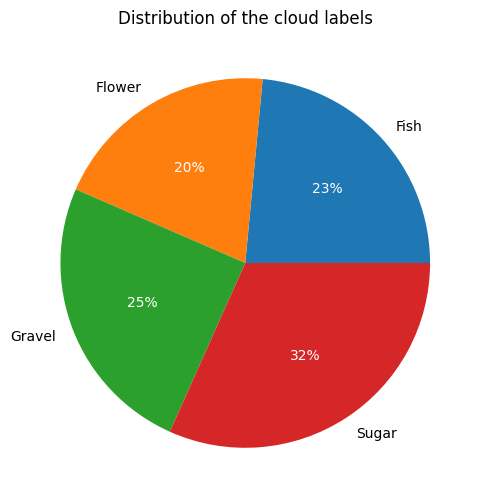

In [5]:
import matplotlib.pyplot as plt

df_no_na = df.dropna()
df_fish = df_no_na[df_no_na['Label']=='Fish']
df_flower = df_no_na[df_no_na['Label']=='Flower']
df_gravel = df_no_na[df_no_na['Label']=='Gravel']
df_sugar = df_no_na[df_no_na['Label']=='Sugar']

fish_count = len(df_fish)
flower_count = len(df_flower)
gravel_count = len(df_gravel)
sugar_count = len(df_sugar)

plt.figure(figsize=(6, 6))
wedges, texts, *rest = plt.pie(
    x=[fish_count, flower_count, gravel_count, sugar_count],
    labels=['Fish', 'Flower', 'Gravel', 'Sugar'],
    autopct='%.0f%%',   # Show percentages - and with no decimals
)

# Set the percentages colors
if len(rest) > 0:           # The autotexts are i rest[0] - but only if the
    autotexts = rest[0]     # `autopct` param is set in the chart.
    for autotext in autotexts:
        autotext.set_color('white')

    plt.title('Distribution of the cloud labels')
    plt.show()


<div class="alert alert-success">✅ Sugar has a much larger share than the others, which have fairly similar shares among themselves. <b>Could that be relevant - maybe in model selection?</b></div>

## Are there any images that have no label?



In [6]:
labels_per_image = df.groupby('Image')['EncodedPixels'].count()
unlabeled_images = labels_per_image[labels_per_image == 0].index.to_list()
print('Number of pictures without labels:', len(unlabeled_images))


Number of pictures without labels: 0


<div class="alert alert-success">✅ In the labels DataFrame there are no images without labels.</div>

## Are there images with multiple labels?

In [7]:
images_per_label_count = labels_per_image.value_counts().sort_index()
images_per_label_count

EncodedPixels
1    1348
2    2372
3    1560
4     266
Name: count, dtype: int64

<div class="alert alert-success">✅ As it turns out, <b>images with only one cloud type are the exception rather than the rule</b>: about three out of four images contain <b>multiple labels</b>.</div>

Let's visualize this fact:

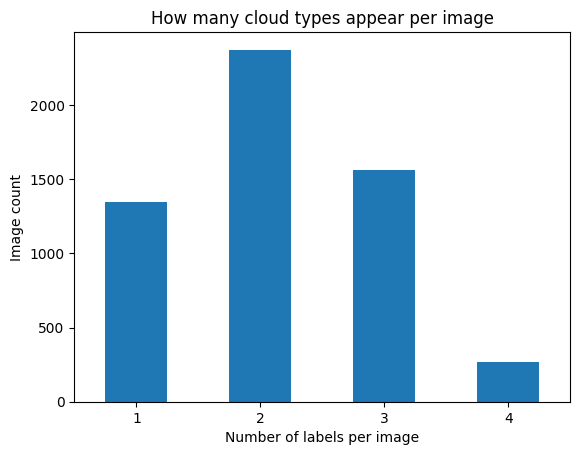

In [8]:
ax = images_per_label_count.plot.bar(rot=0)
ax.set_xlabel('Number of labels per image')
ax.set_ylabel('Image count')
ax.set_title('How many cloud types appear per image')
plt.show()

## How does the images look?

In [ ]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np

from src.utils.rle import decode_rle


@dataclass
class ImageData:
    path: Path
    filename: str
    mask_pixels: np.ndarray
    label_name: str

def display_masked_image(image_data: ImageData):
    # Create a figure with 3 sublots in one row
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    # Read the image
    img = plt.imread(image_data.path / image_data.filename)

    # Display the image
    axes[0].imshow(img)
    axes[0].set_title(image_data.filename)

    # Display the mask
    axes[1].imshow(image_data.mask_pixels, cmap='gray')
    axes[1].set_title(f'Mask: {image_data.filename}')

    # Display the image with a transparent overlay
    axes[2].imshow(img)
    axes[2].imshow(image_data.mask_pixels, cmap='Reds', alpha=0.4)
    axes[2].set_title(f'Mask region labeled as "{image_data.label_name}"')

    # Turn off the scales for all axes
    for ax in axes:
        ax.axis('off')
    plt.show()

def get_image_data(
        image_id: int,
        image_path=TRAIN_PATH,
        image_shape=(1000, 2000)
) -> ImageData:
    filename = df.iloc[image_id]['Image']
    encoded_mask_pixels = df.iloc[image_id]['EncodedPixels']
    label = df.iloc[image_id]['Label']
    decoded_mask_pixels = decode_rle(encoded_mask_pixels, image_shape)
    return ImageData(image_path, filename, decoded_mask_pixels, label)

# Display the first 3 images (with all masks)

## Image 0011165.jpg

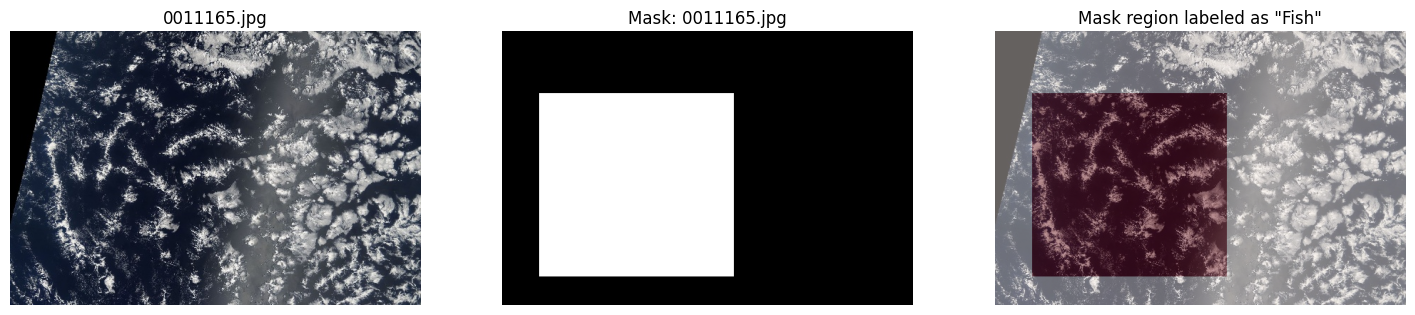

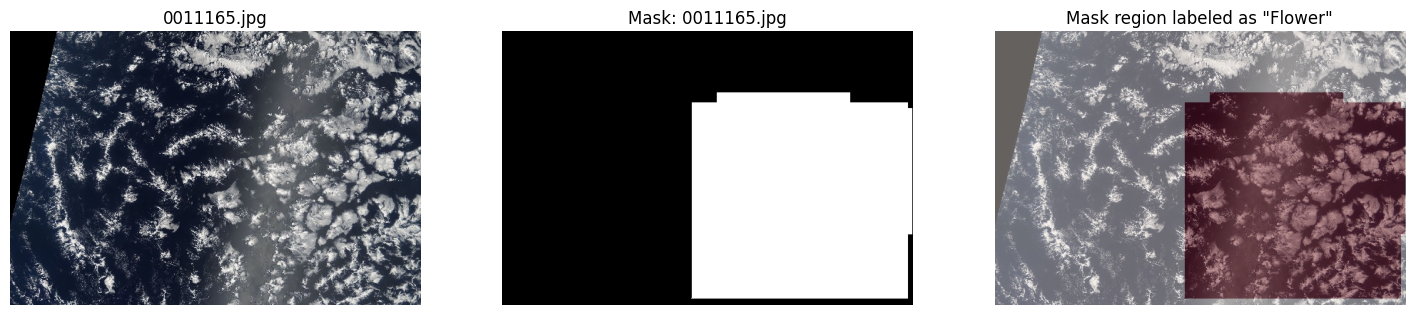

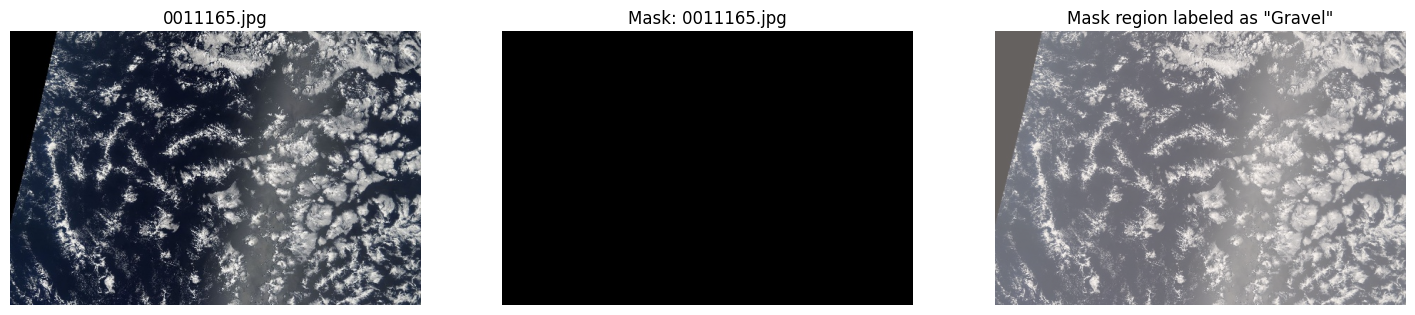

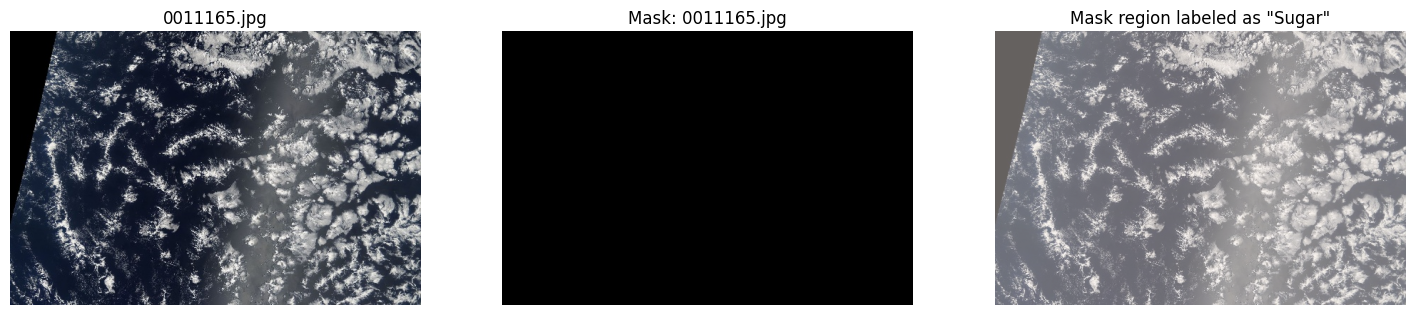

## Image 002be4f.jpg

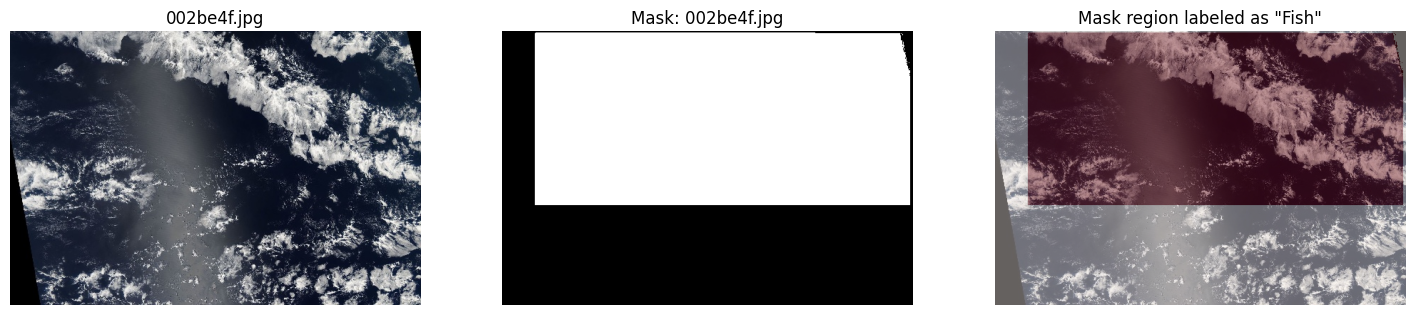

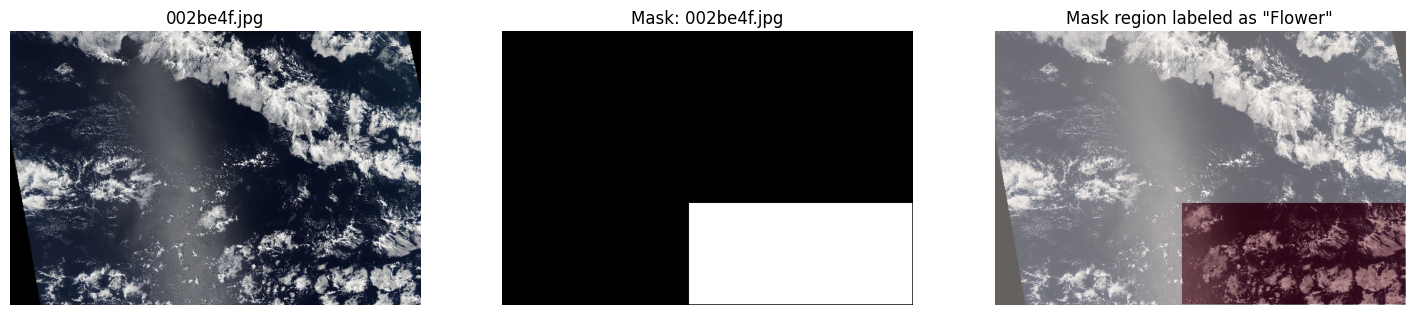

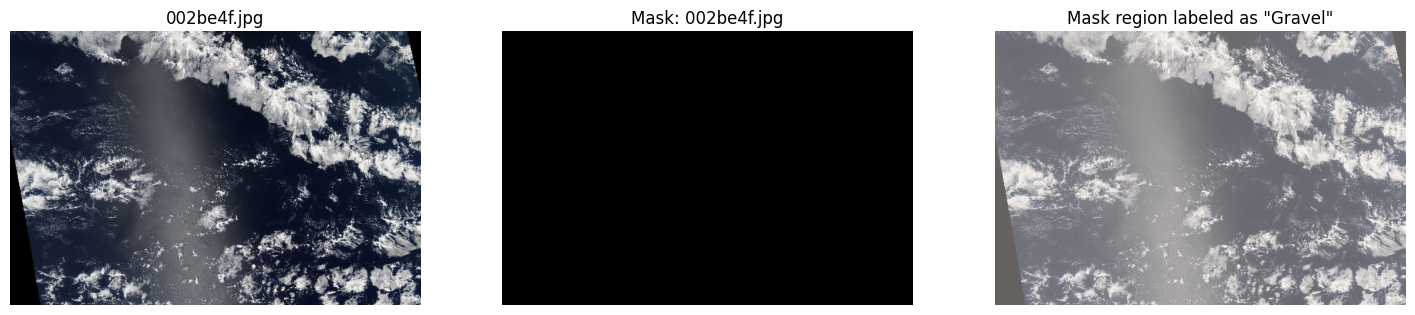

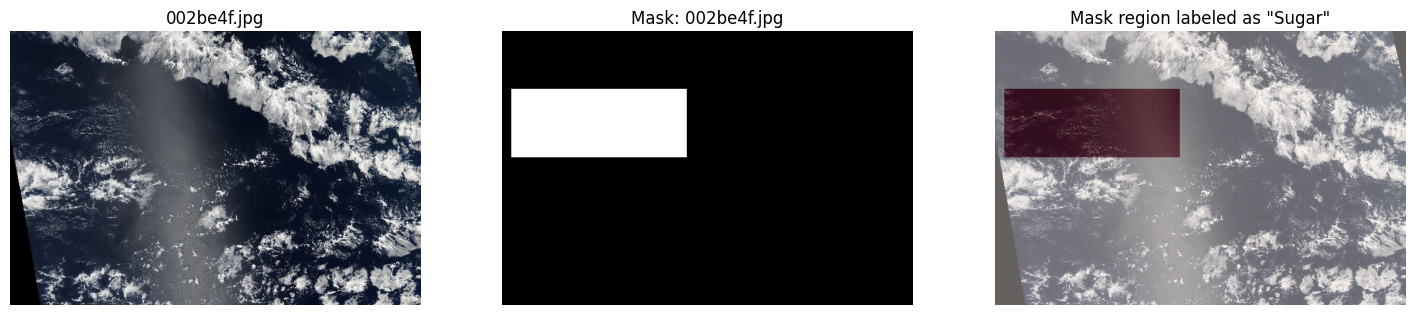

## Image 0031ae9.jpg

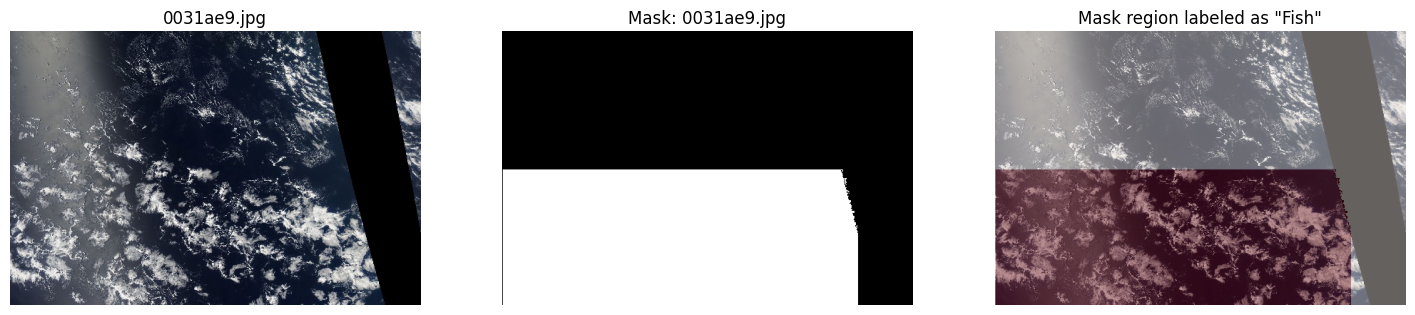

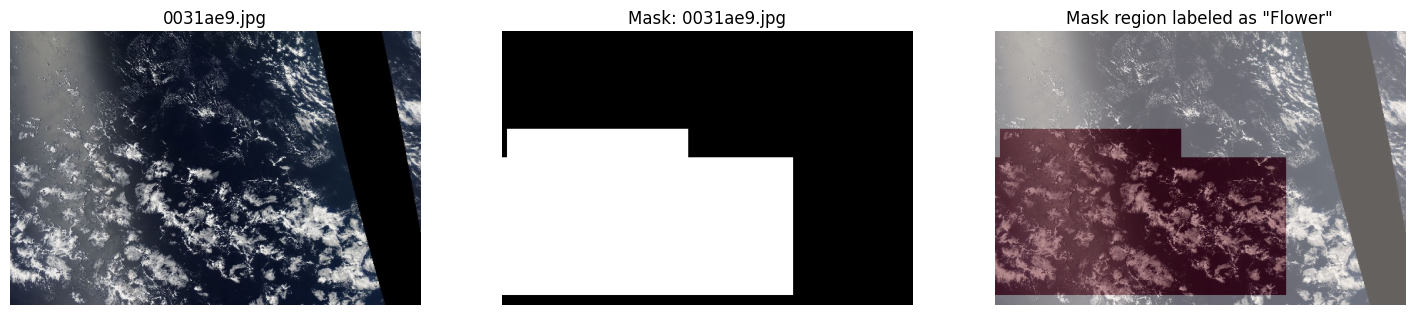

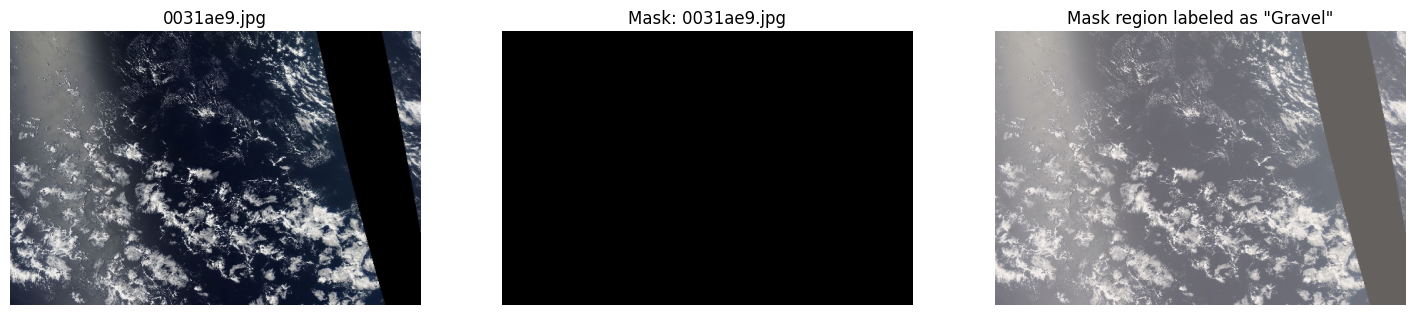

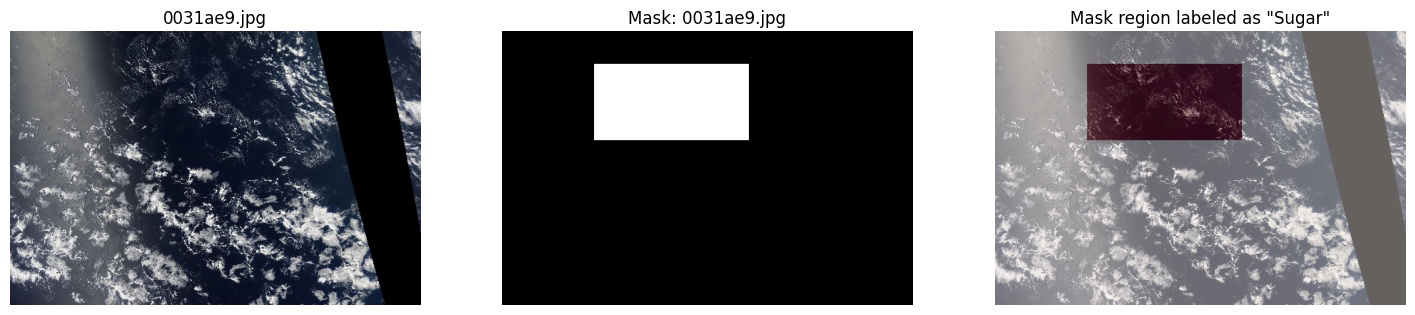

In [11]:
from IPython.display import Markdown, display

# To print 3 images we have to print 12 images (index [0; 11]) because every 
# image has 4 rows
for i in range(12):
    image_data = get_image_data(i)
    if (i % 4) == 0:
        display(Markdown(f'## Image {image_data.filename}'))
    display_masked_image(image_data)

<div class="alert alert-success">✅ Now, this gives a good visual impression what the images look and what the masks represent.</div>

### Where are the labeled masks (top, bottom, left, right)?

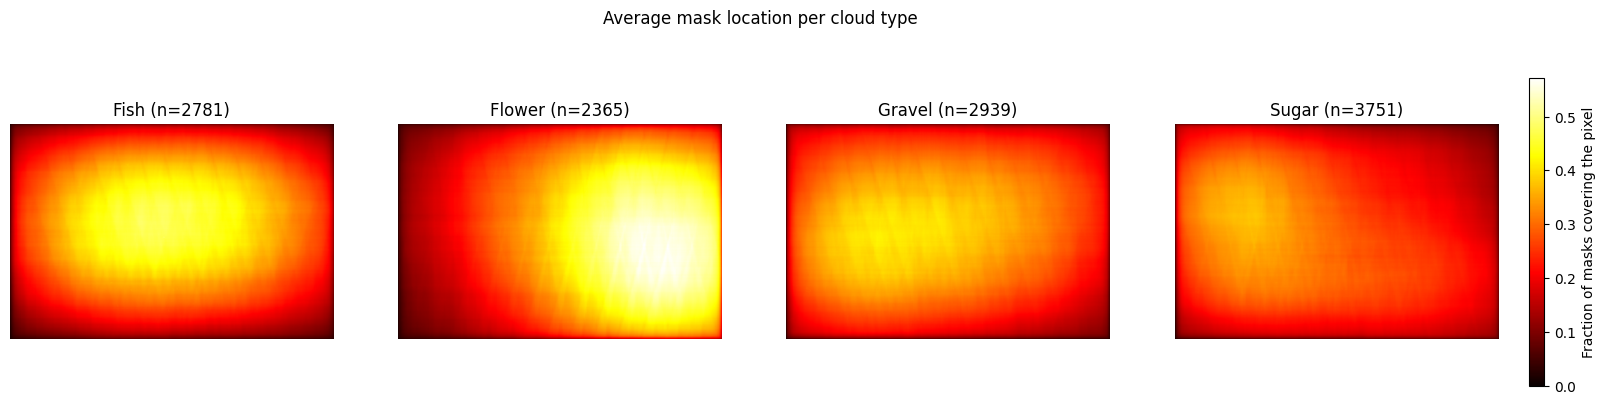

In [11]:
LABELS = ['Fish', 'Flower', 'Gravel', 'Sugar']
IMAGE_SHAPE = (384, 576)

# Create the avg pixel distribution for each of the 4 cloud types
mean_masks = {}
mask_counts = {}
for label in LABELS:
    mask_rows = df[(df['Label'] == label) & df['EncodedPixels'].notna()]
    encoded_masks = mask_rows['EncodedPixels']
    accumulator = np.zeros(IMAGE_SHAPE, dtype=np.float64)
    for encoded in encoded_masks:
        accumulator += decode_rle(encoded, IMAGE_SHAPE)
    mask_counts[label] = len(encoded_masks)
    mean_masks[label] = accumulator / len(encoded_masks)

# Get the common max value to make all heatmaps comparable
vmax = max(mean_mask.max() for mean_mask in mean_masks.values())

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, label in zip(axes, LABELS):
    heatmap = ax.imshow(mean_masks[label], cmap='hot', vmin=0, vmax=vmax)
    ax.set_title(f'{label} (n={mask_counts[label]})')
    ax.axis('off')

# Display one color bar for all subplots
fig.colorbar(
    heatmap,
    ax=axes,
    fraction=0.02,
    pad=0.02,
    label='Fraction of masks covering the pixel'
)
fig.suptitle('Average mask location per cloud type', y=1.05)
plt.show()

<div class="alert alert-warning">⚠️ At this point I'm not quite sure if the average mask location as shown above would help us in model selection.</div>



## Questions / Next Steps

As far as I understand it by now (roughly the supervised-learning workflow):

1. We choose a model.
2. We split the data into a **training** and a **validation** set (the validation set is *not* seen during learning).
3. We feed the model with the training data: the pixels of each image.
4. **Inner loop, the actual learning:**
    - **4.1** The model predicts masks
    - **4.2** They are compared against the true masks
    - **4.3** Then the model automatically adjusts its own **parameters** (weights) to reduce the error
    - **4.4** The model continues with 4.1 for many loops (*"epochs"*) until the error is small enough. ("What is *small enough*"?). Then it returns its results to us.
5. We measure how good the model is on the **validation set**
6. **Outer loop, tuning the model** 
     - **6.1** *We* adjust the **hyperparameters** (learning rate and more) based on the validation score and go back to step 3.
7. Finally, we evaluate once on the real **test set** (the images from the `TEST_PATH`).

But which model can we use that takes pixels as input and presents us masks as result?

